# Snowballing nested sampling

### What is Snowballing nested sampling?

In vanilla nested sampling, a fixed number of K live points is evolved by iteratively replacing the worst likelihood point,
often with a step sampler performing M steps. It is essential that M is large enough, so that the final point decorrelates from the start point, otherwise nested sampling results are biased. However tuning M to be large enough is difficult, because one needs to throw away shorter walks.

The key insight of snowballing nested sampling is that M can be small if K is large - in fact K*M needs to be large enough.
For example, at M=1, the subsequent point is correlated, but if there are so many live points K that the average distance between them is smaller than how far the step sampler managed to walk, it is okay.
Changing K is much easier to implement than chaning M. That is already the approach in dynamic nested sampling, the number of live points is iteratively changed.

Snowballing nested sampling runs with a small population of live points K=50 until the highest likelihood. Then it adds an additional population of another K live points and runs this, and keeps rerunning and doubling the number of live points. In an analogy of a snowball growing in size as it rolls until one can build a snowman, we call these iterations snowball rotations. Within each snowball rotation, nested sampling runs its iterations until a convergence criterion (until the live points have negligible posterior weight). Across snowball rotations, the average distance between live points becomes smaller and smaller, and the fixed step sampler length M becomes more and more acceptable. In the process lnZ converges to the true value. No evaluations are ever discarded.

### How many rotations should be performed?

For convergence testing, we use the jump distance, the distance between start of a chain and end point, relative to the average distance between live points. This relative jump distance (RJD) increases with snowball rotations, because the distances become smaller and smaller, approximately linearly with rotation number. At some point, the jump distances become indistinguishable from average distances.

### Properties of snowballing nested sampling

Snowballing nested sampling has key benefits over vanilla and dynamic nested sampling:

* quick look posteriors are available from the first rotation
* a fixed compute budget (maximum number of likelihood calls, maximum executation time) can be assigned for the run
* high sample size of the posterior distribution by keeping all intermediate states

Snowballing nested sampling implements vectorized step sampling so that the likelihood function is
called with a batch of P points (always the same number in a rotation).

## Model and data


Let's set up our model of a periodic signal:

In [1]:
import numpy as np
from numpy import sin, pi

def sine_model1(t, B, A1, P1, t1):
    return A1 * sin((t / P1 + t1) * 2 * pi) + B

def sine_model2(t, B, A1, P1, t1, A2, P2, t2):
    return A1 * sin((t / P1 + t1) * 2 * pi) + A2 * sin((t / P2 + t2) * 2 * pi) + B

np.random.seed(42)

n_data = 50
t = np.random.uniform(0, 5, size=n_data)
yerr = 1.0
y = np.random.normal(sine_model2(t, B=1.0, A1=4.2, P1=3, t1=0, A2=1.2, P2=1.2, t2=1.2), yerr)

parameters2 = ['B', 'A1', 'P1', 't1', 'A2', 'P2', 't2']


## Visualise the data


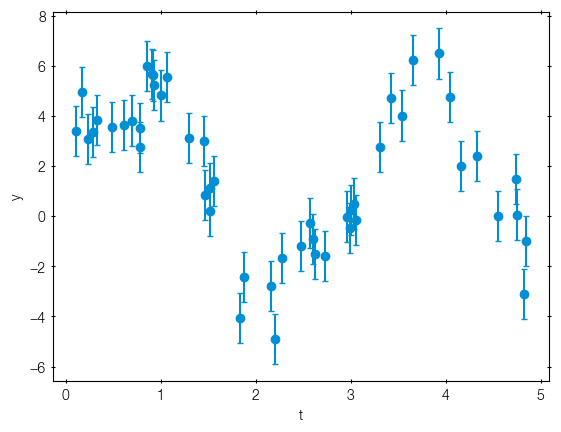

In [2]:
%matplotlib inline
import matplotlib.pyplot as plt

plt.figure()
plt.xlabel('t')
plt.ylabel('y')
plt.errorbar(x=t, y=y, yerr=yerr, ls='none', marker='o');


Set up the (vectorized) prior transform from the unit cube to physical parameters,
and ou likelihood function.

In [3]:
def prior_transform(cube):
    params = cube.copy()
    # let background level go from -10 to +10
    params[:, 0] = cube[:, 0] * 20 - 10
    # let amplitude go from 0.1 to 100
    params[:, 1] = 10**(cube[:, 1] * 3 - 1)
    # let period go from 0.3 to 30
    params[:, 2] = 10**(cube[:, 2] * 2)
    # let time go from 0 to 1
    params[:, 3] = cube[:, 3]
    params[:, 4] = 10**(cube[:, 4] * 3 - 1)
    params[:, 5] = 10**(cube[:, 5] * 2)
    params[:, 6] = cube[:, 6]
    return params

def log_likelihood(params):
    B, A1, P1, t1, A2, P2, t2 = params.transpose()
    # evaluate the model for all points at once:
    # y_model has shape (n_data, n_points)
    y_model = sine_model2(
        t[:, None], B=B[None, :], A1=A1[None, :], P1=P1[None, :],
        t1=t1[None, :], A2=A2[None, :], P2=P2[None, :], t2=t2[None, :])
    loglike = -0.5 * (((y_model - y[:, None]) / yerr)**2).sum(axis=0)
    # avoid unnecessary multiple solutions:
    #    force ordering by period from large to small
    swap = P1 < P2
    loglike[swap] = -1e300 * np.abs(P1[swap] - P2[swap])
    return loglike


## Setting up the sampler

The `SnowballingNestedSampler` takes a vectorized prior transform and a
vectorized likelihood function (arrays of points in, array of
likelihoods out), and a `log_dir` where the growing HDF5 point store,
the rotation records and the plots are written.

Its main settings:

* the number of live points starts at `num_live_points_base` (default 50)
  and doubles with each rotation (widening);
* `P` (default: half the live points, capped at 100) threads are advanced
  per batch advance;
* the direction proposal is a step sampler function, by default the
  quadratic slice direction;
* the region proposal pool (the points the directions are drawn from) is
  padded with the most recent dead points to at least `min_point_pool`
  (default 400), so small `K` still keeps proposal diversity;
* the `integrator='custom'` path integrates the dead points with `1/K`
  strips inside the state machine.


In [4]:
from ultranest.snowballingns import SnowballingNestedSampler

sampler = SnowballingNestedSampler(
    parameters2, log_likelihood, transform=prior_transform,
    vectorized=True, num_steps=1, #integrator='custom',
    num_live_points_base=50,
    log_dir='chains/snowball-quicklook')


## Quick-look result: a single rotation

`run(max_rotations=1)` performs a single snowball rotation: the `K=50`
threads are advanced in batches of `P=25` until the `frac_remain`
criterion fires, and the buried dead points are integrated with `1/K`
strips. The corner plot is written to `log_dir` after the rotation.


In [5]:
result = sampler.run(frac_remain=0.5, resume=False, max_num_live_points=50)

[ultranest.SnowballingNestedSampler] Snowball rotation 1[K=50] iter 958 (14800 likelihood function evaluations), lnZ = -53.8362 +- 0.7153

logZ = -53.836 +- 0.715

    B                   : 0.583 │▁▁▁▄▇▅▄▂▆▇▄▂▁▃▁▁▁   ▁             ▁▁▂▁▁▁│0.785     0.635 +- 0.043
    A1                  : 0.341 │▁▁▁▁▇▄▁▂▄▄▁▁▂▄▃▃▆▂▂▁▁▁▁▁  ▁       ▁▁▁▃▁▁│0.569     0.418 +- 0.051
    P1                  : 0.485 │▁▁▁▁▃▂▂▁▂▂▃▁▁▁▂▂▇▂▃▁▁▁▁ ▁▁ ▂▁▁▁▂▁▁▁▁▁▁▁▁│0.683     0.560 +- 0.042
    t1                  : 0.484 │▁▁▁▁ ▁▁▁ ▃▂▂▁▁▂▁▂▂▂▇▂▁▁▁▁▁▁▁▁▂▁  ▁▁▁ ▂▂▁│0.639     0.555 +- 0.034
    A2                  : 0.5099│▁▁▁ ▁▂▁▁▁▁▇▇▃▅▃▆▆▆▃▂▃▅▆▁▂▁▁▁▁▁▁ ▁      ▁│0.5459    0.5240 +- 0.0047
    P2                  : 0.2312│▁ ▁▁▁▁▁▂▁▇▂▂▆▄▃▄▃▃▅▂▃▁▂▁▁▁▁▂▅▁▁▁▁▃     ▁│0.2517    0.2403 +- 0.0040
    t2                  : 0.000 │▆▇▄▃▇▃▂▂▂▁▁▁▁▂▂▄▃▁▁▂▂▂▁▁▂▂▁▇▁▁▁ ▁ ▁▁  ▁▁│0.040     0.012 +- 0.010

[ultranest.SnowballingNestedSampler] Gompertz convergence: needs at least 3 rotations
[ultranest.SnowballingNestedSampler] max_num_live_po

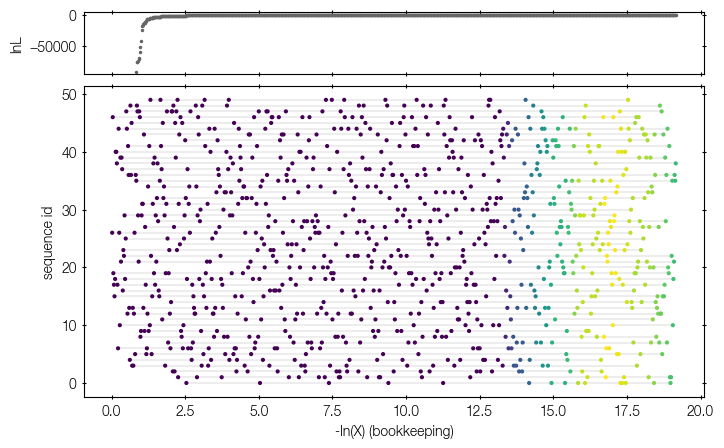

In [6]:
rotation_records, results, gm_history = sampler._load_plot_data()
fig = plt.figure(figsize=(8, 5))
gs = fig.add_gridspec(2, 1, height_ratios=[1, 5], hspace=0.06)
axL = fig.add_subplot(gs[0])
axS = fig.add_subplot(gs[1], sharex=axL)
xmax = 0.0
sc = None
for records in rotation_records:
    xs = np.asarray([r['x'] for r in records])
    Lmin = np.asarray([r['Lmin'] for r in records])
    threads = np.asarray([r['thread'] for r in records])
    for thread in np.unique(threads):
        m = threads == thread
        axS.plot(xs[m], np.full(int(m.sum()), thread), '-',
                 color='gray', lw=0.2, zorder=1)
    sc = axS.scatter(xs, threads, c=Lmin + -xs, cmap='viridis', s=4,
                     zorder=2, vmin=(Lmin + -xs).max() - 3)
    Lmin[Lmin < Lmin.max() - 1e5] = -np.inf
    axL.plot(xs, Lmin, 'o', ms=1.5, color='0.4')
    xmax = max(xmax, float(xs.max()))
axL.set_ylabel('lnL')
plt.setp(axL.get_xticklabels(), visible=False)
axS.set_xlabel('-ln(X) (bookkeeping)')
axS.set_ylabel('sequence id')
#if sc is not None:
#    cb = fig.colorbar(sc, ax=axS, pad=0.01)
#    cb.set_label('posterior weight')
fig

In [7]:
fig, ax = plt.subplots()
sampler.plot_panel_rjd(ax=ax);

In [8]:
from ultranest.plot import cornerplot
cornerplot(result);

### Reading the output

The printed line `rotation 1: K=50, N buried cells, lnZ = ... +- ...`
reports:

* `K` – the number of live points (threads) used in this rotation;
* `N buried cells` – how many dead points passed the burial gate; each is
  one completed walk, integrated with a `1/K` strip;
* `lnZ +- ...` – the evidence integrated so far, plus the estimated error
  `sqrt(H/K)` (the information divided by the live points).

The final line `convergence criterion fulfilled: False` reports whether
the Gompertz looping criterion fired. With a single rotation it cannot:
this is *not* a converged result.

The corner plot shows the quick-look posterior: the buried dead points,
weighted by their `1/K` strips, plus the thread ends, weighted by the
remaining volume. After one rotation the remaining-volume term still
holds a large share of the probability mass, so the evidence is only
partial and the posterior is broad — it is a look at where the sampler
is, not a final answer.


## Full run

The full run lets the rotations widen `K` until the Gompertz looping
criterion says the next doubling is not worth it. The `max_ncalls` and
`max_time` budgets terminate the run at the next rotation boundary even
if the criterion has not fired — and `results['converged']` records
whether it did. The final corner plot is written as `corner.pdf`.


In [9]:
full_sampler = SnowballingNestedSampler(
    parameters2, log_likelihood, transform=prior_transform,
    vectorized=True, num_steps=1, #integrator='custom',
    log_dir='chains/snowball-full')

result = full_sampler.run(
    frac_remain=0.5, max_ncalls=4000000, max_execution_time_in_s=2*60*60, resume=False)


[ultranest.SnowballingNestedSampler] Snowball rotation 1[K=50] iter 864 (14425 likelihood function evaluations), lnZ = -50.9323 +- 0.6679

logZ = -50.932 +- 0.668

    B                   : 0.532 │▁▄▅▇▂▁▁▁▁▅▃▁▂▂▁▂▂▂▃▂▁▂▁▁▂▂▂▃▅▂▂▃▁▁▁▁ ▁ ▁│0.571     0.547 +- 0.011
    A1                  : 0.010 │▁▃▇▂▁▁▁▁▁▃▁▁ ▁▁▁▁▁▁▁▁▁▁▁ ▁▁▁▁▁▁▁▁▁▂▁▄▁▁▁│0.188     0.079 +- 0.063
    P1                  : 0.35  │▁  ▁▆▂▁▁▁▁▁▁▁ ▁▁▁▁▁▁▁▂▁ ▁▁▁▁▃▃▇▁▁▁▁▃   ▁│0.78      0.59 +- 0.12
    t1                  : 0.205 │▁▁▁▁▃▇▁▁▃▁▁▂▁▁ ▁▁ ▁  ▁▁  ▁▁▁▁▁▁▂▃▂▁    ▁│0.481     0.304 +- 0.083
    A2                  : 0.5083│▁  ▁▁▂ ▁▂▂▁▁▂▃▁▂▄▄▄▄▄▃▅▇▇▂▁▂▂▃▂▂▃▄▃▁ ▁ ▁│0.5452    0.5287 +- 0.0067
    P2                  : 0.2367│▁▁ ▁▂▂▃▃▅▇▃▃▃▅▇▅▇▄▃▁▁▁▁▁▁▁▁▂▂▁▁▁▁▁ ▁   ▁│0.2601    0.2448 +- 0.0037
    t2                  : 0.000 │▁▃▅▂▁▂▂▃▇▃▃▁▁▁ ▁▁▃▁▁▁▁▁▁▁  ▁▁▁▁ ▁▁▂▁▁▁ ▁│0.069     0.019 +- 0.016

[ultranest.SnowballingNestedSampler] Gompertz convergence: needs at least 3 rotations


/tmp/ipykernel_618582/3309219119.py:27: RuntimeWarning: overflow encountered in multiply
  loglike[swap] = -1e300 * np.abs(P1[swap] - P2[swap])


[ultranest.SnowballingNestedSampler] Snowball rotation 2[K=100] iter 1776 (33650 likelihood function evaluations), lnZ = -51.5994 +- 0.4900

logZ = -51.599 +- 0.490

    B                   : 0.16  │▁▃▁▁▁▁▃▃▁▁▁                         ▇▅▅▃│0.57      0.43 +- 0.16
    A1                  : 0.01  │▇▁▂▁▁▂▁▁▁▂▂▁                        ▁▅▂▃│0.64      0.27 +- 0.27
    P1                  : 0.35  │▁ ▁▅▁▁▁▁▁ ▁▁▁▁▂▁▁▁▁▂▇▃▁▁▂  ▁       ▁▄▂▂▇│0.97      0.73 +- 0.19
    t1                  : 0.205 │▁▁▁▁▂▇▃▁▂▁▁▁▁▁▁▁▁▁   ▁▁  ▁▁ ▁▁ ▁▂▁▁    ▁│0.481     0.276 +- 0.066
    A2                  : 0.5047│▁  ▁▁▁▁▁▁▂▁▁▁▂▁▃▂▂▂▂▂▇▁▂▂▂▂▂▄▂▂▂▁▁▁▁ ▁▁▁│0.5517    0.5301 +- 0.0075
    P2                  : 0.2322│▁ ▁▁▁▁▁▂▃▄▅▄▆▇▇▃▃▄▆▄▆▂▁▁▁▁▁▁▁▁▂▁ ▁▁ ▁  ▁│0.2601    0.2433 +- 0.0040
    t2                  : 0.00  │▇▂▁▁                                  ▁▆│1.00      0.38 +- 0.47

[ultranest.SnowballingNestedSampler] Gompertz convergence: needs at least 3 rotations
[ultranest.SnowballingNestedSampler] Snowball rotation 3[K

/tmp/ipykernel_618582/3309219119.py:23: RuntimeWarning: overflow encountered in square
  loglike = -0.5 * (((y_model - y[:, None]) / yerr)**2).sum(axis=0)
/home/user/.local/lib/python3.12/site-packages/numpy/_core/_methods.py:51: RuntimeWarning: overflow encountered in reduce
  return umr_sum(a, axis, dtype, out, keepdims, initial, where)


[ultranest.SnowballingNestedSampler] Snowball rotation 6[K=1600] iter 45550 (911850 likelihood function evaluations), lnZ = -45.7117 +- 0.1696

logZ = -45.712 +- 0.170

    B                   : 0.5302│▁▁ ▁ ▁▁▁▁▁▁▁▁▁▁▁▁▇▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁│0.5721    0.5482 +- 0.0014
    A1                  : 0.5117│▁▁ ▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▇▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁│0.5631    0.5410 +- 0.0020
    P1                  : 0.22799│▁  ▁▁▁▁▁▁▁▁▁▁▁▁▁▇▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁ ▁ ▁ ▁│0.24973    0.23700 +- 0.00067
    t1                  : 0.009 │▁▁                                    ▁▇│1.000     0.981 +- 0.038
    A2                  : 0.2510│▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▇▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁│0.4307    0.3418 +- 0.0076
    P2                  : 0.0308│▁▁▁ ▁▁▁▁▁▁▁▁▁▇▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁│0.0665    0.0431 +- 0.0014
    t2                  : 0.143 │▁▁▁ ▁▁▁▁▁▁▁▁▁▁▇▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁   ▁│0.405     0.239 +- 0.010

[ultranest.SnowballingNestedSampler] Gompertz convergence: 18/20 segments predicted to improve in the next rotation


/tmp/ipykernel_618582/3309219119.py:6: RuntimeWarning: overflow encountered in power
  params[:, 1] = 10**(cube[:, 1] * 3 - 1)
/tmp/ipykernel_618582/3309219119.py:11: RuntimeWarning: overflow encountered in power
  params[:, 4] = 10**(cube[:, 4] * 3 - 1)


[ultranest.SnowballingNestedSampler] Snowball rotation 7[K=3200] iter 88575 (1815275 likelihood function evaluations), lnZ = -44.3863 +- 0.1185

logZ = -44.386 +- 0.119

    B                   : 0.5272│▁  ▁ ▁▁▁▁▁▁▁▁▁▁▁▁▁▂▁▁▁▁▁▁▁▇▁▁▁▁▁▁▁▁▁▁▁ ▁│0.5680    0.5518 +- 0.0034
    A1                  : 0.5161│▁  ▁▁  ▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▂▇▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁│0.5633    0.5444 +- 0.0014
    P1                  : 0.2292│▁ ▁▁▁▁▁▁▁▁▁▇▁▁▁▁▂▁▁▁▁▁▁▁▁▁▁            ▁│0.2536    0.2369 +- 0.0012
    t1                  : 0.007 │▁▁▁                                   ▁▇│1.000     0.982 +- 0.013
    A2                  : 0.2731│▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▂▇▁▁▁▁▁▁▁▁▁▁▁▁▁ ▁▁│0.4240    0.3603 +- 0.0057
    P2                  : 0.0320│▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▂▁▁▇▁▁▁▁▁▁▁▁▁▁▁▁▁  ▁ ▁▁│0.0646    0.0479 +- 0.0018
    t2                  : 0.144 │▁▁▁▁▁▁▁▁▁▁▁▁▂▁▁▁▁▁▁▁▁▇▁▁▁▁▁▁▁▁▁▁▁▁▁ ▁▁▁▁│0.370     0.254 +- 0.022

[ultranest.SnowballingNestedSampler] Gompertz convergence: 1/20 segments predicted to improve in the next rotation


/tmp/ipykernel_618582/1847774291.py:8: RuntimeWarning: invalid value encountered in add
  return A1 * sin((t / P1 + t1) * 2 * pi) + A2 * sin((t / P2 + t2) * 2 * pi) + B
/tmp/ipykernel_618582/1847774291.py:8: RuntimeWarning: divide by zero encountered in divide
  return A1 * sin((t / P1 + t1) * 2 * pi) + A2 * sin((t / P2 + t2) * 2 * pi) + B
/tmp/ipykernel_618582/1847774291.py:8: RuntimeWarning: invalid value encountered in sin
  return A1 * sin((t / P1 + t1) * 2 * pi) + A2 * sin((t / P2 + t2) * 2 * pi) + B
/tmp/ipykernel_618582/3309219119.py:12: RuntimeWarning: overflow encountered in power
  params[:, 5] = 10**(cube[:, 5] * 2)


[ultranest.SnowballingNestedSampler] Snowball rotation 8[K=6400] iter 188125 (3887100 likelihood function evaluations), lnZ = -45.5048 +- 0.0859

logZ = -45.505 +- 0.086

    B                   : 0.5292│▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▂▁▁▁▁▁▁▁▇▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁│0.5718    0.5517 +- 0.0034
    A1                  : 0.5128│▁   ▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▂▇▁▁▁▁▁▁▁▁▁▁▁▁▁▁│0.5638    0.5444 +- 0.0014
    P1                  : 0.2292│▁▁ ▁▁▁▁▁▁▁▇▁▁▁▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁   ▁▁▁│0.2556    0.2370 +- 0.0012
    t1                  : 0.000 │▁▁▁                                   ▁▇│1.000     0.980 +- 0.046
    A2                  : 0.2429│▁ ▁  ▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▃▇▁▁▁▁▁▁▁▁▁▁▁▁▁│0.4247    0.3602 +- 0.0058
    P2                  : 0.0318│▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▂▁▁▇▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁ ▁▁▁▁│0.0661    0.0479 +- 0.0018
    t2                  : 0.116 │▁ ▁ ▁▁▁▁▁▁▁▁▁▂▁▁▁▁▁▁▁▇▁▁▁▁▁▁▁▁▁ ▁▁▁▁ ▁▁▁│0.399     0.254 +- 0.022

[ultranest.SnowballingNestedSampler] Gompertz convergence: 0/20 segments predicted to improve in the next rotation
[ultranest

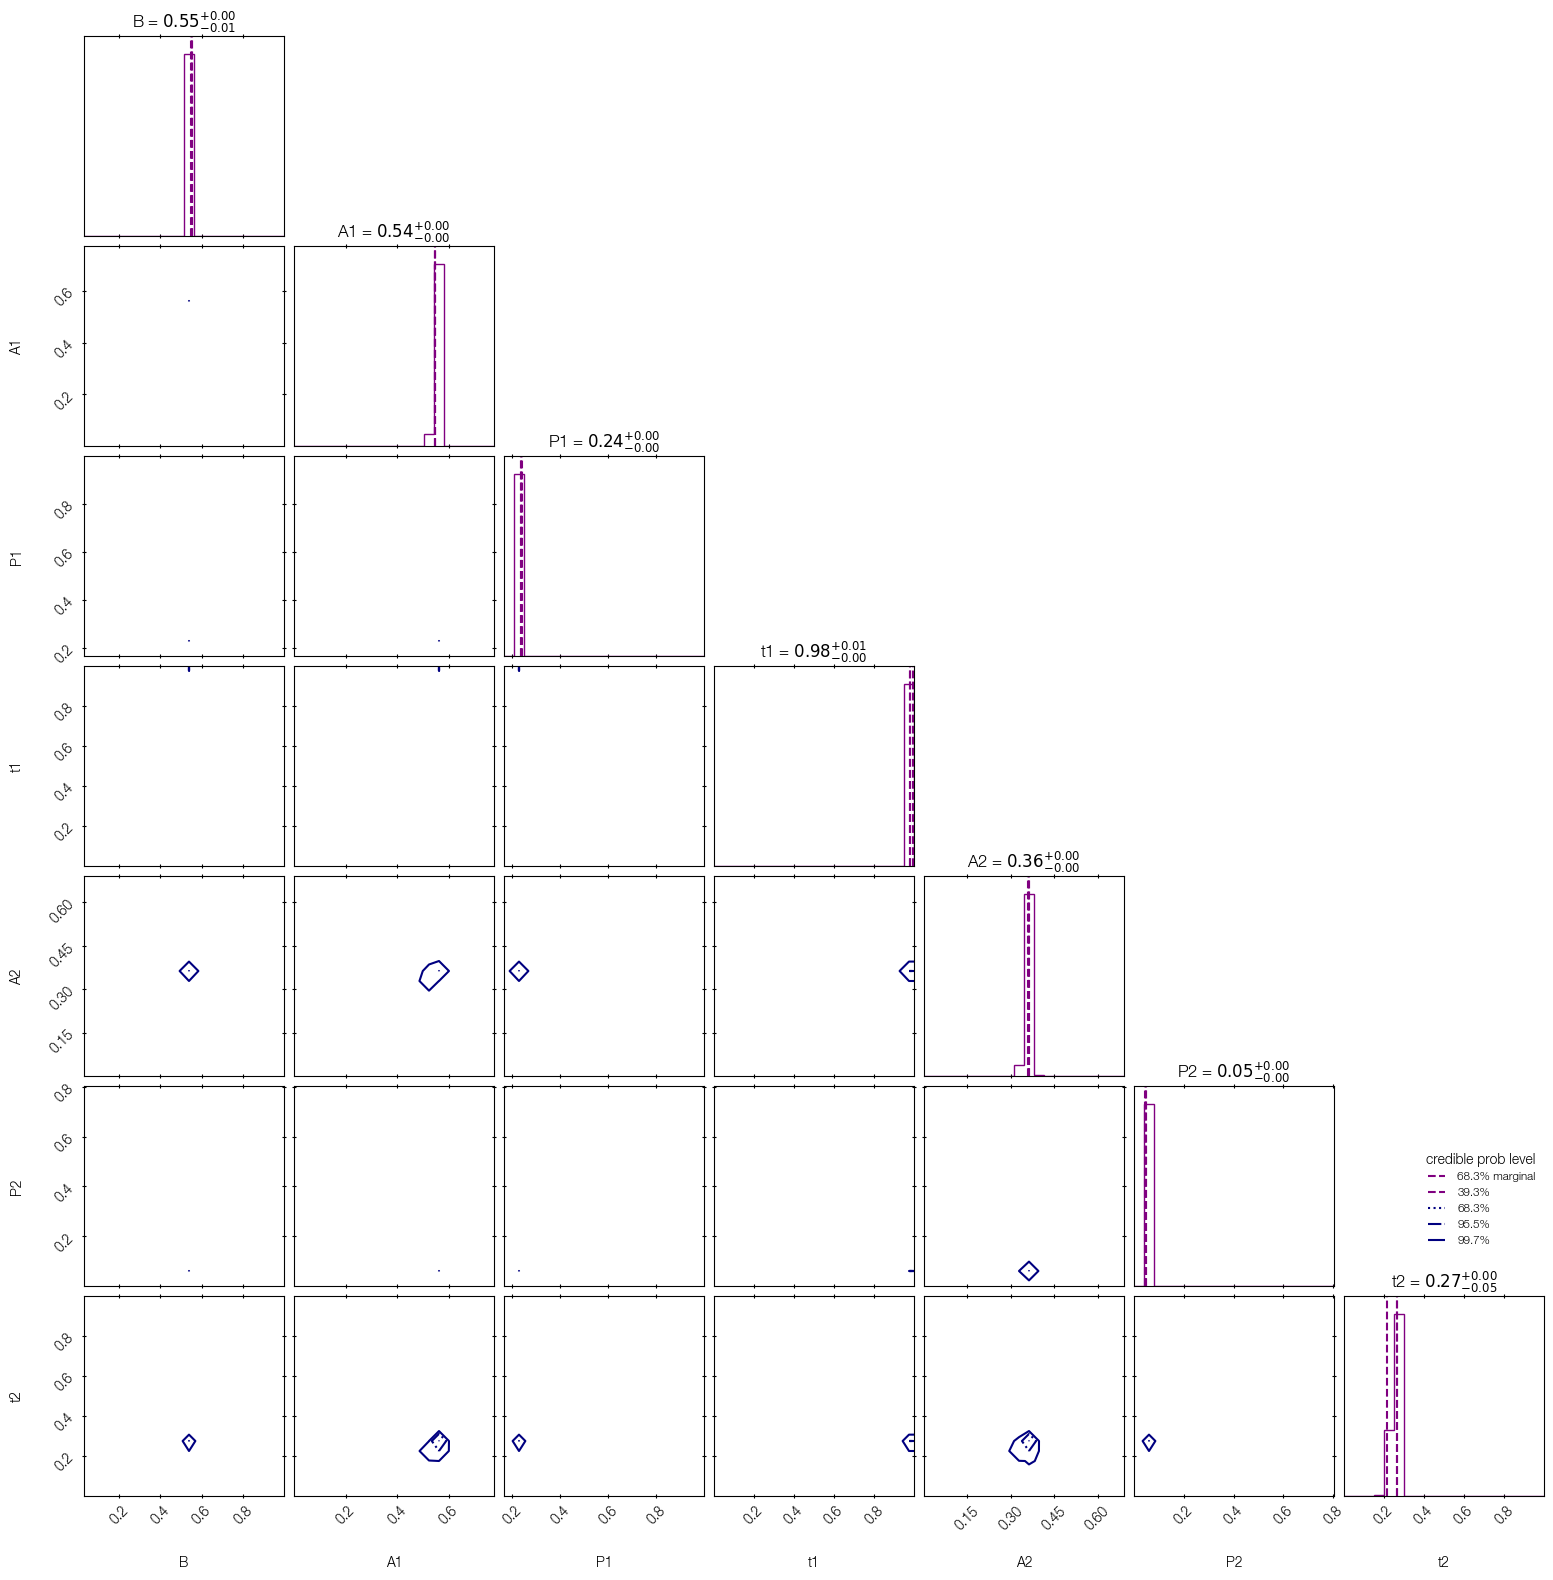

In [10]:
cornerplot(result)

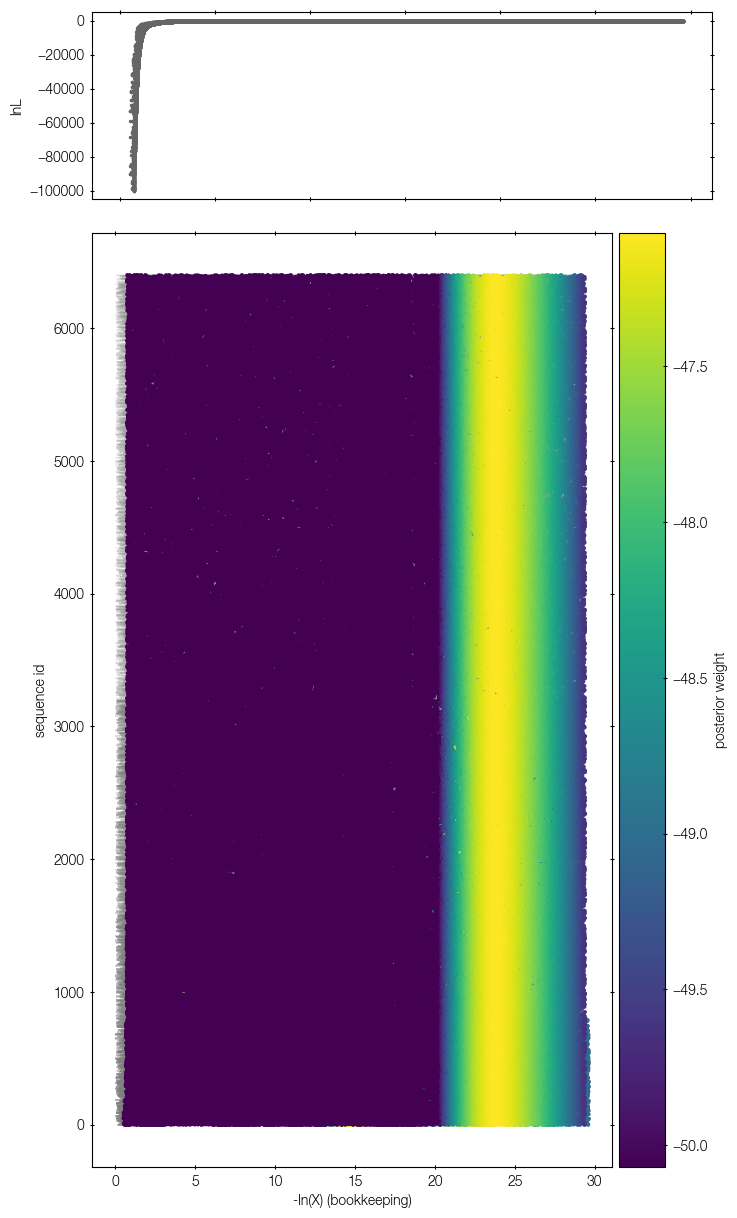

In [15]:
rotation_records, results, gm_history = full_sampler._load_plot_data()
fig = plt.figure(figsize=(8, 15))
gs = fig.add_gridspec(2, 1, height_ratios=[1, 5], hspace=0.06)
axL = fig.add_subplot(gs[0])
axS = fig.add_subplot(gs[1], sharex=axL)
xmax = 0.0
sc = None
for records in rotation_records:
    xs = np.asarray([r['x'] for r in records])
    Lmin = np.asarray([r['Lmin'] for r in records])
    Lmin[Lmin < Lmin.max() - 1e5] = -np.inf
    threads = np.asarray([r['thread'] for r in records])
    for thread in np.unique(threads):
        m = threads == thread
        axS.plot(xs[m], np.full(int(m.sum()), thread), '-',
                 color='gray', lw=0.2, zorder=1)
    sc = axS.scatter(xs, threads, c=Lmin + -xs, cmap='viridis', s=4,
                     zorder=2, vmin=(Lmin + -xs).max() - 3)
    axL.plot(xs, Lmin, 'o', ms=1.5, color='0.4')
    xmax = max(xmax, float(xs.max()))
axL.set_ylabel('lnL')
plt.setp(axL.get_xticklabels(), visible=False)
axS.set_xlabel('-ln(X) (bookkeeping)')
axS.set_ylabel('sequence id')
if sc is not None:
    cb = fig.colorbar(sc, ax=axS, pad=0.01)
    cb.set_label('posterior weight')
fig

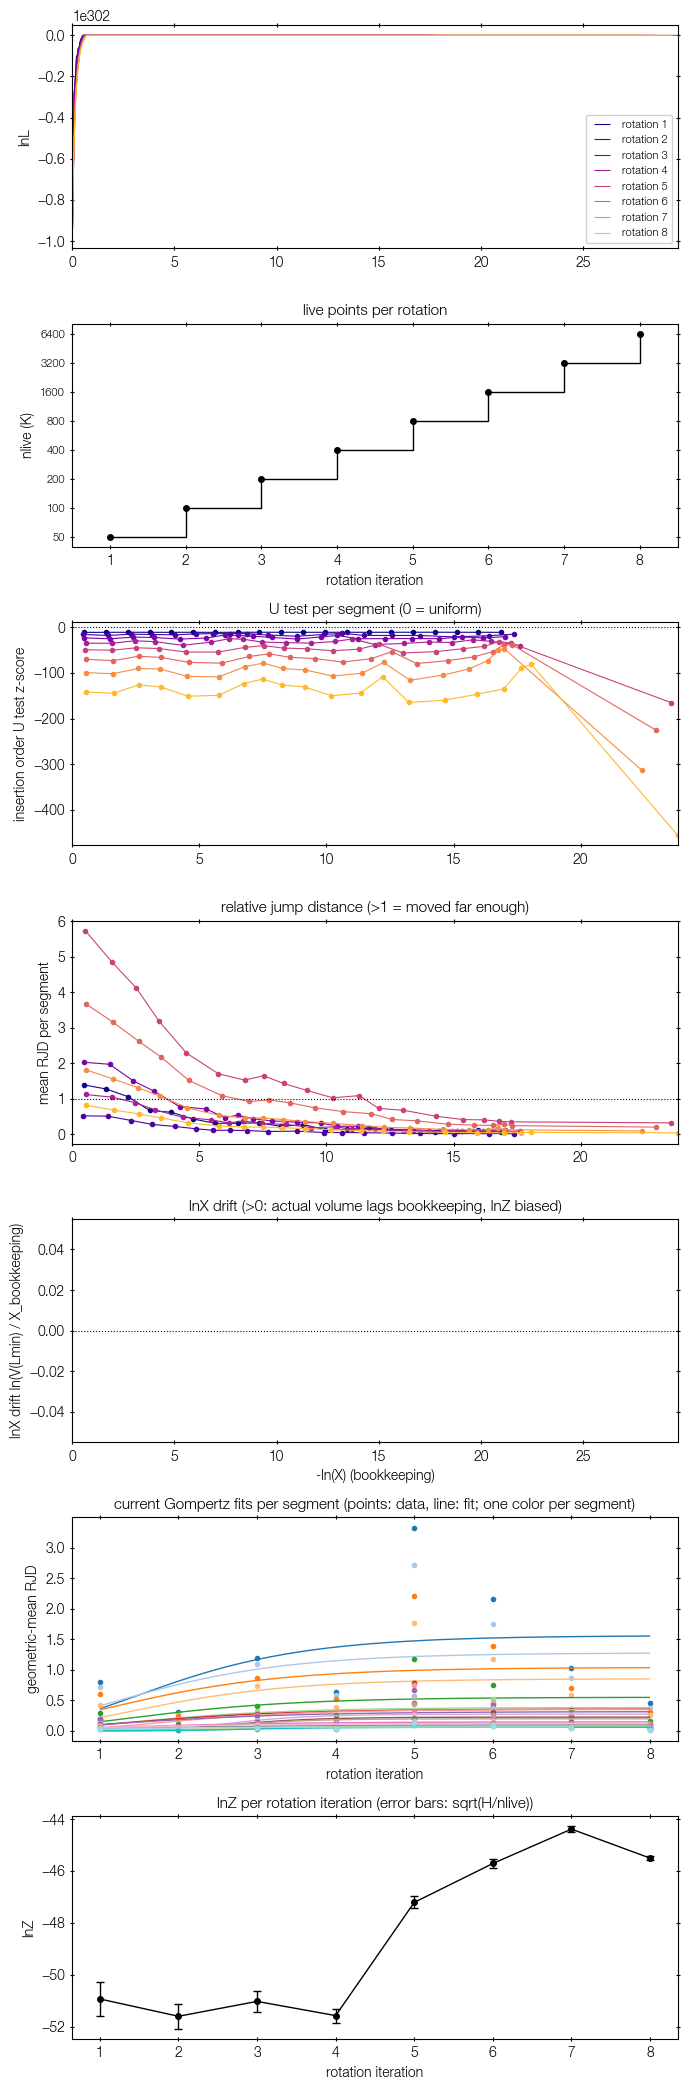

In [12]:
full_sampler.plot_rotations()

In [13]:
print('lnZ = %.3f +- %.3f' % (result['logz'], result['logzerr']))
print('converged:', result['converged'])


lnZ = -45.505 +- 0.086
converged: True


The corner plot now shows the posterior from the accumulated dead
points of all rotations, weighted by their strips, with the thread ends
contributing only a small remaining-volume weight. The `K` of the last
rotation is the accuracy knob: the error estimate scales as
`sqrt(H/K)`.